## **IMPORT LIBRARIES**

In [201]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore')

## **DATA LOADING**

In [202]:
'''
Load dataset tiket bioskop
'''

df = pd.read_csv('datasets/cinemaTicket_Ref.csv')

In [203]:
'''
Periksa informasi dataset
'''

# Menampilkan 5 baris pertama dataset
display(df.head())
# Menampilkan jumlah baris dan kolom dataset
print(f"\nJumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}\n")
# Menampilkan informasi dataset
display(df.info())
# Menampilkan ringkasan statistik dataset
display(df.describe())

,film_code,cinema_code,total_sales,tickets_sold,tickets_out,show_time,occu_perc,ticket_price,ticket_use,capacity,date,month,quarter,day
0,1492,304,3900000,26,0,4,4.26,150000.0,26,610.328638,2018-05-05,5,2,5
1,1492,352,3360000,42,0,5,8.08,80000.0,42,519.801980,2018-05-05,5,2,5
2,1492,489,2560000,32,0,4,20.00,80000.0,32,160.000000,2018-05-05,5,2,5
3,1492,429,1200000,12,0,1,11.01,100000.0,12,108.991826,2018-05-05,5,2,5
4,1492,524,1200000,15,0,3,16.67,80000.0,15,89.982004,2018-05-05,5,2,5



Jumlah baris: 142524, Jumlah kolom: 14

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142524 entries, 0 to 142523
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   film_code     142524 non-null  int64  
 1   cinema_code   142524 non-null  int64  
 2   total_sales   142524 non-null  int64  
 3   tickets_sold  142524 non-null  int64  
 4   tickets_out   142524 non-null  int64  
 5   show_time     142524 non-null  int64  
 6   occu_perc     142399 non-null  float64
 7   ticket_price  142524 non-null  float64
 8   ticket_use    142524 non-null  int64  
 9   capacity      142399 non-null  float64
 10  date          142524 non-null  object 
 11  month         142524 non-null  int64  
 12  quarter       142524 non-null  int64  
 13  day           142524 non-null  int64  
dtypes: float64(3), int64(10), object(1)
memory usage: 15.2+ MB


None

,film_code,cinema_code,total_sales,tickets_sold,tickets_out,show_time,occu_perc,ticket_price,ticket_use,capacity,month,quarter,day
count,142524.000000,142524.000000,1.425240e+05,142524.000000,142524.000000,142524.000000,142399.000000,142524.000000,142524.000000,142399.000000,142524.000000,142524.000000,142524.000000
mean,1518.985111,320.378427,1.234728e+07,140.137570,0.237413,3.932103,19.965986,81234.599886,139.900157,854.723605,6.776852,2.634721,16.112585
std,36.184450,159.701229,3.065486e+07,279.758733,2.923206,3.056276,22.653445,33236.599278,279.564935,953.118103,2.195843,0.809692,8.949471
min,1471.000000,32.000000,2.000000e+04,1.000000,0.000000,1.000000,0.000000,483.870968,-219.000000,-2.000000,2.000000,1.000000,1.000000
25%,1485.000000,181.000000,1.260000e+06,18.000000,0.000000,2.000000,3.750000,60000.000000,18.000000,276.994486,5.000000,2.000000,8.000000
50%,1498.000000,324.000000,3.720000e+06,50.000000,0.000000,3.000000,10.350000,79454.235185,50.000000,525.714286,7.000000,3.000000,16.000000
75%,1556.000000,474.000000,1.110000e+07,143.000000,0.000000,5.000000,28.210000,100000.000000,143.000000,1038.961039,9.000000,3.000000,24.000000
max,1589.000000,637.000000,1.262820e+09,8499.000000,311.000000,60.000000,147.500000,700000.000000,8499.000000,9692.097160,11.000000,4.000000,31.000000


## **DATA CLEANING**

In [204]:
'''
Mengambil variabel yang dbutuhkan
'''

data = df[['date', 'tickets_sold']]

display(data.head())
display(data.info())

,date,tickets_sold
0,2018-05-05,26
1,2018-05-05,42
2,2018-05-05,32
3,2018-05-05,12
4,2018-05-05,15


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142524 entries, 0 to 142523
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   date          142524 non-null  object
 1   tickets_sold  142524 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 2.2+ MB


None

In [205]:
'''
Konversi kolom 'date' menjadi tipe data datetime
'''

data['date'] = pd.to_datetime(data['date'])

display(data.head())
display(data.info())

,date,tickets_sold
0,2018-05-05,26
1,2018-05-05,42
2,2018-05-05,32
3,2018-05-05,12
4,2018-05-05,15


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142524 entries, 0 to 142523
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          142524 non-null  datetime64[ns]
 1   tickets_sold  142524 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


None

In [206]:
'''
Grouping data per jadi per hari
'''

# Menghitung jumlah tiket yang terjual per hari
data = data.groupby('date')['tickets_sold'].sum().reset_index()
display(data)

,date,tickets_sold
0,2018-02-21,267
1,2018-02-23,3
2,2018-03-14,20104
3,2018-03-15,41274
4,2018-03-16,51761
...,...,...
229,2018-10-31,47644
230,2018-11-01,80694
231,2018-11-02,86748
232,2018-11-03,45485


In [207]:
'''
Set kolom 'date' sebagai index
'''

data.set_index('date', inplace=True)
data.index

data.head()

,tickets_sold
date,
2018-02-21,267
2018-02-23,3
2018-03-14,20104
2018-03-15,41274
2018-03-16,51761


In [208]:
'''
Mengurut data harian dan Handling missing values
'''

# Menggunakan metode bfill untuk mengisi nilai yang hilang
data = data.asfreq('D', method='bfill')

data.head()

,tickets_sold
date,
2018-02-21,267
2018-02-22,3
2018-02-23,3
2018-02-24,20104
2018-02-25,20104


## **DATA VISUALIZATION**

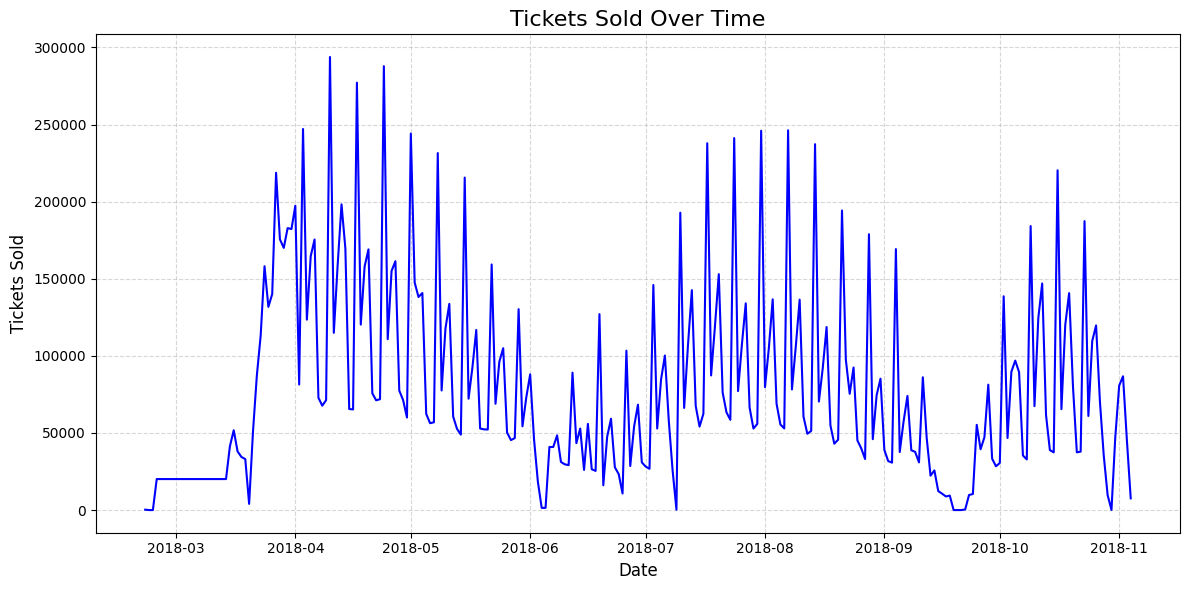

In [209]:
'''
Menampilkan plot dari data tiket yang terjual
'''

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data.index, data['tickets_sold'], linestyle='-', color='b')

ax.set_title('Tickets Sold Over Time', fontsize=16)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Tickets Sold', fontsize=12)

ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

```
Insight: Data multiplicative dan seasonality terjadi setiap mingguan/7 hari. (murni dilihat dari kasat mata)
```

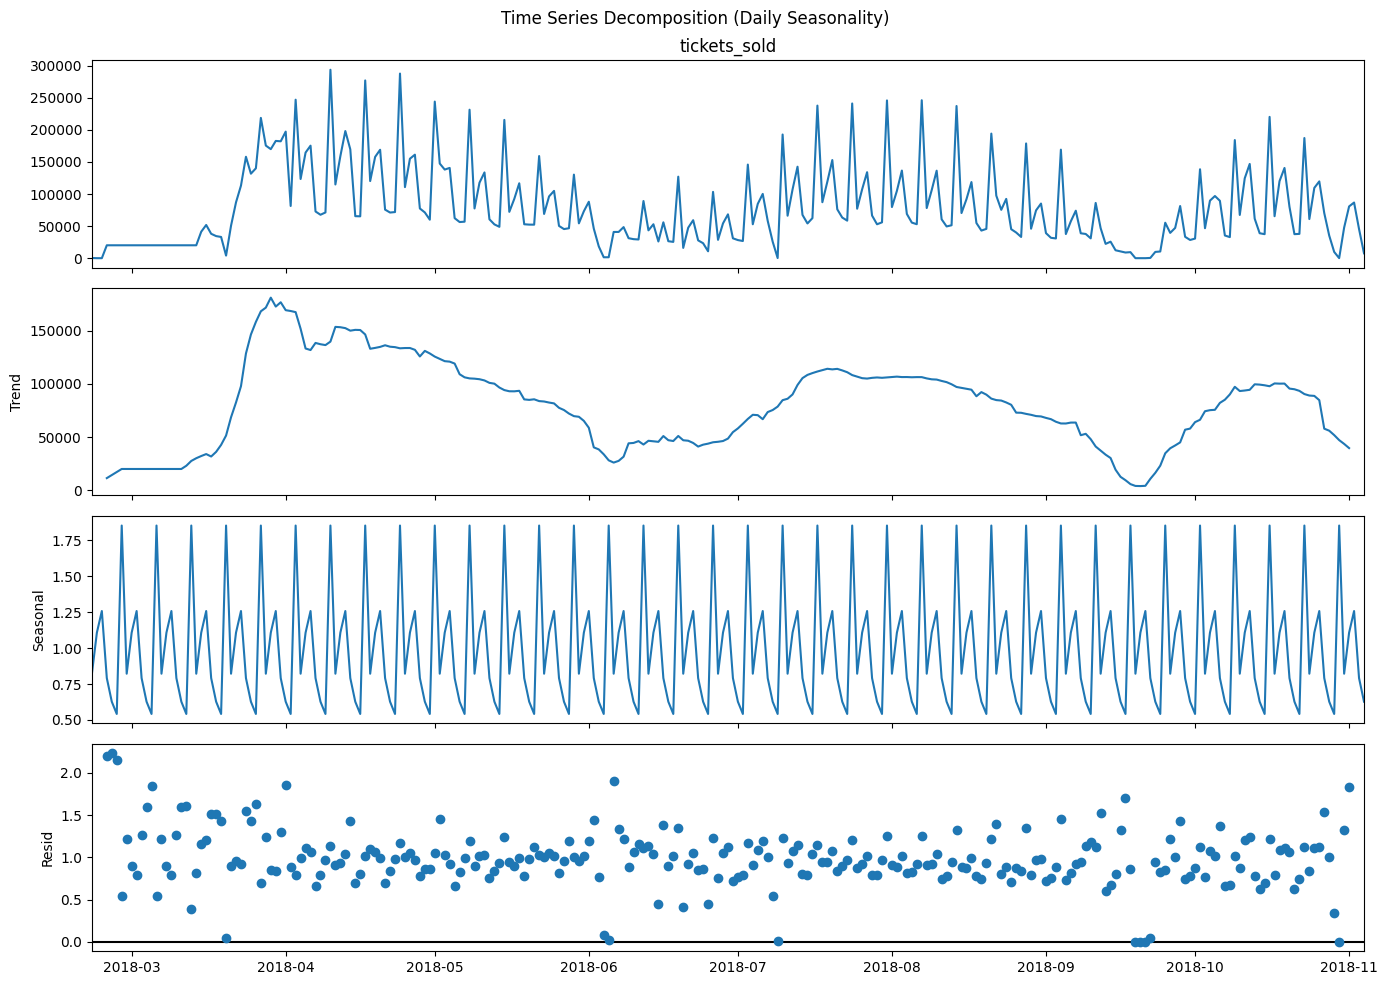

In [210]:
decomposition = seasonal_decompose(data['tickets_sold'], model='multiplicative', period=7)
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.suptitle('Time Series Decomposition (Daily Seasonality)')
plt.tight_layout()
plt.show()

## **SPLITING TRAIN & TEST**

In [211]:
'''
Spliting data train dan test
'''

# Mengambil data 21 hari untuk test dan sisanya untuk train
len_train = round(len(data) - 21)

data_train = data[:len_train]
data_test = data[len_train:]

print(f"total train: {len_train}")
print(f"total test: {len(data)-len_train}")

total train: 236
total test: 21


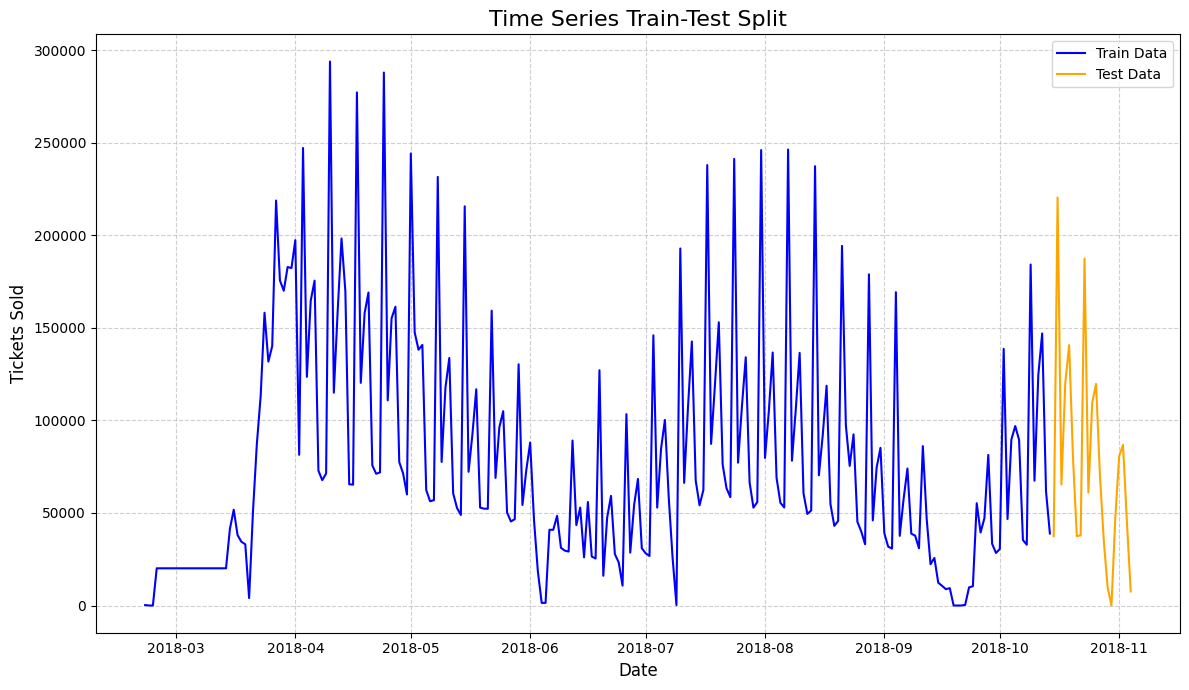

In [212]:
'''
Visualisasi data train dan test
'''

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(data_train.index, data_train['tickets_sold'], color='blue', label='Train Data')
ax.plot(data_test.index, data_test['tickets_sold'], color='orange', label='Test Data')

ax.set_title('Time Series Train-Test Split', fontsize=16)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Tickets Sold', fontsize=12)

ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## **STATIONARY CHECK**

In [213]:
'''
Stationarity test using Augmented Dickey-Fuller test
'''

def perform_adf_test(series: pd.Series, series_name: str = "the series"):
    """
    Performs and prints the results of the Augmented Dickey-Fuller test.

    Args:
        series (pd.Series): The time series data to test.
        series_name (str): A descriptive name for the data being tested.
    """
    print(f"--- ADF Test Results for: {series_name} ---")

    # Perform the ADF test
    result = adfuller(series.dropna()) # dropna() is important for differenced series

    # Print the main results
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value}')

    # Print the conclusion
    print('\n--- Conclusion ---')
    if result[1] <= 0.05:
        print("The data is likely stationary.")
    else:
        print("The data is likely non-stationary.")
    print("-" * 40)

perform_adf_test(data_train['tickets_sold'], series_name="Raw Training Data")

--- ADF Test Results for: Raw Training Data ---
ADF Statistic: -2.5702624162144065
p-value: 0.09930048743378078
Critical Values:
	1%: -3.460018927623594
	5%: -2.8745897386146817
	10%: -2.57372514086348

--- Conclusion ---
The data is likely non-stationary.
----------------------------------------


```
Insight: Data masih belum stationary.

Tindakan: Lakukan differencing.
```

## **DIFFERENCING**

In [214]:
'''
Differencing orde 1
'''

data_diff = data_train.diff().dropna()

adf_test(data_diff, 'Data Train Setelah Differencing Orde 1')

ADF Test: Data Train Setelah Differencing Orde 1
ADF Statistic: -4.953312959823885
p-value: 2.7432502487621446e-05
Critical Values:
  1%: -3.460154163751041
  5%: -2.874648939216792
  10%: -2.5737567259151044
Kesimpulan: Data stasioner. H0 ditolak.


```
Insight: Data sudah stasioner. Lanjut ke tahap selanjutnya.
```

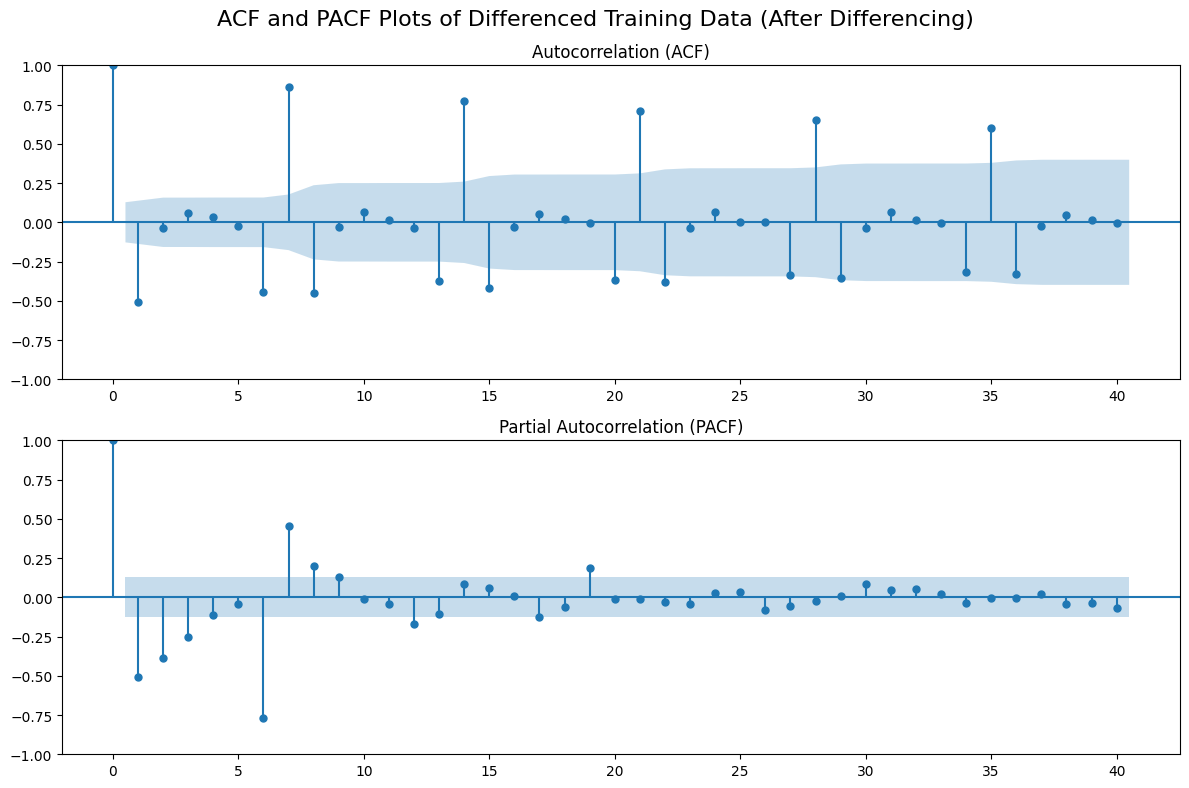

In [215]:
'''
ACF dan PACF data
'''

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
fig.suptitle('ACF and PACF Plots of Differenced Training Data (After Differencing)', fontsize=16)
plot_acf(data_diff['tickets_sold'], ax=ax1, lags=40)
ax1.set_title('Autocorrelation (ACF)')
plot_pacf(data_diff['tickets_sold'], ax=ax2, lags=40)
ax2.set_title('Partial Autocorrelation (PACF)')
plt.tight_layout()
plt.show()

```
Insight:
- Kedua data ACF dan PACF cenderung cuts off, sehingga model yang dipakai adalah ARIMA(p,q).
- Nilai p = [1, 2, 3, 6, 7, 8, 12, 19]
- Nilai q = [1, 7, 8, 13, 14, 15, 20, 21, 22, 28, 35]
- Nilai d = 1
```

## **MODELING**

In [221]:
'''
Definisi model ARIMA dan SARIMA
'''

# ARIMA
# Menggunakan parameter (2,1,8) saja
arima = ARIMA(data_train['tickets_sold'], order = (2,1,8))

# SRAIMA
# Menggunakan parameter (1,1,0) saja dengan seasonal_order (1,1,0,7)
sarima = SARIMAX(data_train['tickets_sold'], order= (1,1,1), seasonal_order = (1,1,0, 7))

In [222]:
'''
Training and predict model ARIMA dan SARIMA
'''

model_arima = arima.fit()
model_sarima = sarima.fit()

forecast_arima = model_arima.forecast(steps=len(data_test))
forecast_sarima = model_sarima.forecast(steps=len(data_test))

In [223]:
'''
ARIMA results
'''

arima_results = []

mae = mean_absolute_error(data_test['tickets_sold'], forecast_arima)
mape = mean_absolute_percentage_error(data_test['tickets_sold'], forecast_arima) * 100
arima_results.append({
            'model': 'ARIMA',
            'AIC': model_arima.aic,
            'BIC': model_arima.bic,
            'MAE': mae,
            'MAPE': mape
        })
arima_results_df = pd.DataFrame(arima_results).sort_values('MAPE')
arima_results_df

,model,AIC,BIC,MAE,MAPE
0,ARIMA,5707.139638,5745.195079,37326.261663,5336.643967


In [224]:
'''
SARIMA results
'''

sarima_results = []

mae = mean_absolute_error(data_test['tickets_sold'], forecast_sarima)
mape = mean_absolute_percentage_error(data_test['tickets_sold'], forecast_sarima) * 100
sarima_results.append({
            'model': 'SARIMA',
            'AIC': model_sarima.aic,
            'BIC': model_sarima.bic,
            'MAE': mae,
            'MAPE': mape
        })
sarima_results_df = pd.DataFrame(sarima_results).sort_values('MAPE')
sarima_results_df

,model,AIC,BIC,MAE,MAPE
0,SARIMA,5362.103633,5375.821016,39591.862797,14445.394807


```
Insight: Model SARIMA memiliki nilai AIC dan BIC lebih kecil dibandingkan model ARIMA, dapat dinyatakan bahwa model considered yang terbaik karena mampu menjelaskan datanya dan lebih simpel. Hal ini juga terlihat dari nilai MAPE nya yang lebih kecil daripada model ARIMA.
```

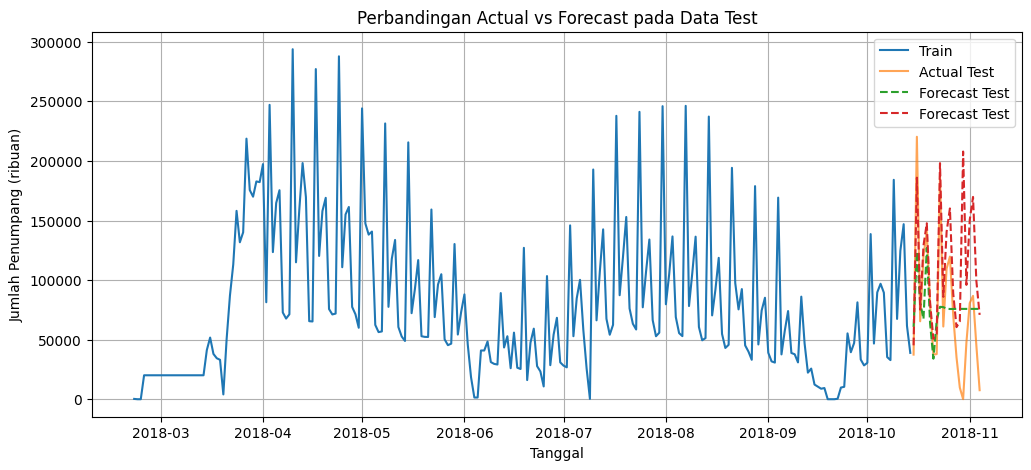

In [ ]:
'''
Forecast vs Actual Test
'''

plt.figure(figsize=(12, 5))
plt.plot(data_train.index, data_train['tickets_sold'], label='Train')
plt.plot(data_test.index, data_test['tickets_sold'], label='Actual Test', alpha=0.7)
plt.plot(data_test.index, forecast_arima, label='Forecast Test', linestyle='--')
plt.plot(data_test.index, forecast_sarima, label='Forecast Test', linestyle='--')
plt.title('Perbandingan Actual vs Forecast pada Data Test')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penumpang (ribuan)')
plt.legend()
plt.grid(True)  
plt.show()

```
Insight: Hasil model SARIMA mampu memprediksi data test secara penuh daripada model ARIMA yang terpotong di tengah.
```

In [239]:
'''
Model inference selama seminggu kedepan
'''

forecast_steps = 7

sarima = SARIMAX(data['tickets_sold'], order= (1,1,1), seasonal_order = (1,1,0, 7))

future_forecast = sarima.fit().forecast(steps=forecast_steps)

future_df = pd.DataFrame({
    'forecast_tickets_sold': future_forecast
})

display(future_df.head())
print('Tanggal terakhir dataset:', data.index.max())
print('Tanggal awal forecast:', future_df.index.min())
print('Tanggal akhir forecast:', future_df.index.max())

,forecast_tickets_sold
2018-11-05,-17780.044026
2018-11-06,5687.336782
2018-11-07,17176.355312
2018-11-08,53447.539449
2018-11-09,60347.072193


Tanggal terakhir dataset: 2018-11-04 00:00:00
Tanggal awal forecast: 2018-11-05 00:00:00
Tanggal akhir forecast: 2018-11-11 00:00:00


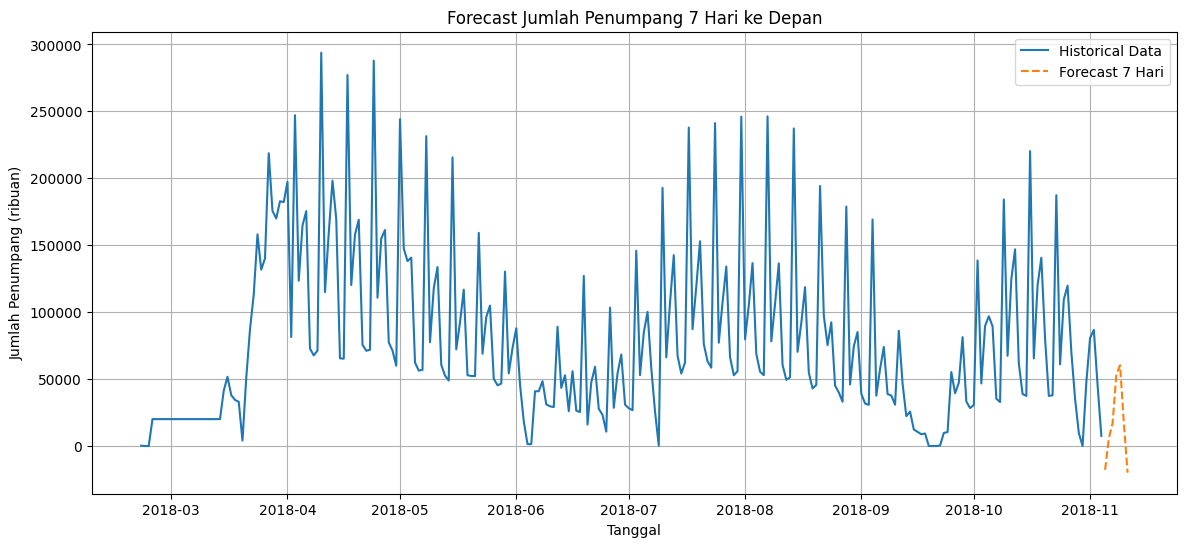

In [240]:
'''
Visualisasi hasil prediksi selama seminggu kedepan
'''

plt.figure(figsize=(14, 6))
plt.plot(data.index, data['tickets_sold'], label='Historical Data')
plt.plot(future_df.index, future_df['forecast_tickets_sold'], label='Forecast 7 Hari', linestyle='--')
plt.title('Forecast Jumlah Penumpang 7 Hari ke Depan')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penumpang (ribuan)')
plt.legend()
plt.grid(True)
plt.show()

```
Insight: Berdasarkan hasil forecast, penjualan tiket seminggu kedepan mengalami penurunan, terutama pada tanggal 2018-11-05 hingga 2018-11-11. Pihak bioskop perlu mempertimbangkan strategi bisnis sebagai berikut:
- Optimasi jumlah studio dan jam tayang per hari. Jangan terlalu banyak menggunakan studio per film nya dan jadwalnya dalam periode harian untuk saving budget.
- Memotong masa tayang film (jika memang ada film yang sedang tidak laku pada waktu tersebut)
- Menampilkan ulang film yang cukup terkenal (misal release ulang film Marvel), untuk mengisi pendapatan sementara.
- Meningkatkan kinerja sektor pada F&B (biasanya kalo di XXI kan ada cafe nya jadi dijadikan pertimbangan) untuk meningkatkan minat konsumen.
```